# Monitoreo y experimento de deriva

Un modelo desplegado se degrada cuando los datos que recibe dejan de parecerse a los de entrenamiento, y casi nunca hay etiquetas inmediatas para notarlo. En este capítulo respondemos RQ8: **¿cómo se degrada el rendimiento ante deriva de datos, y con qué rapidez y potencia la detecta el monitoreo?** Inyectamos deriva controlada y gradual sobre flujos simulados con los dos modelos servidos, medimos la caída real de la métrica y evaluamos detectores que no necesitan etiquetas. Los resultados los generan `python scripts/mlops.py drift` (texto) y `python scripts/mlops.py drift-image` (imágenes).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.metrics import roc_auc_score, roc_curve

from project.analysis_nlp import LABELS as LBL_TXT
from project.analysis_seg import LABELS as LBL_SEG
from project.book_utils import CAT, MUTED, exists, need, style

style()
pd.set_option("display.precision", 3)
md = lambda t: display(Markdown(t))  # noqa: E731

## Qué monitoreamos

| Dimensión | Señal implementada | Dónde |
|---|---|---|
| Deriva de covariables | PSI de la longitud del texto y de la intensidad media de la imagen; MMD sobre la proyección SVD-50 del TF-IDF (solo si el modelo servido es lineal) y sobre las señales de imagen estandarizadas | `src/project/drift.py`, `src/project/mlops.py` |
| Deriva de predicciones | χ² de la distribución de clases predichas; PSI y KS de la confianza; z del número de instancias por imagen | ídem |
| Deriva de concepto | F1 macro o AP por ventana cuando llegan etiquetas tardías | ventanas deslizantes del experimento |
| Operacional | peticiones, errores y latencia p50/p95/p99 por ruta | `/metrics` y `/metrics/prometheus` (Prometheus + Grafana) |
| Calidad de entrada | longitud del texto, tipo y tamaño de imagen, esquema de la petición | validación de FastAPI/Pydantic en la API |

Cada detector compara una ventana de producción con la referencia de validación. El umbral de alarma es el percentil 95 del estadístico en ventanas **sin deriva**, de modo que la tasa de falsas alarmas nominal es del 5 % por ventana.

## Texto

Escenarios sobre ventanas de 60 currículos de test, 200 repeticiones por nivel:

- **Errores tipográficos**: intercambio de dos letras adyacentes en el 0 al 30 % de las palabras de 4 o más letras (cambio de vocabulario).
- **Truncado** a las primeras 400, 200, 100 o 50 palabras (cambio de longitud y de contenido).
- **Cambio de la mezcla de clases**: cuatro clases elegidas al azar se sobremuestrean hasta 11 veces (cambio de temas).

Modelo monitoreado: DistilBERT. Umbrales (p95 sin deriva): PSI de la confianza 0.308, PSI de la longitud 0.403, χ² de clases predichas 27.2. Sin calcular: MMD (SVD-50). El MMD proyecta el TF-IDF del modelo servido con SVD-50; con DistilBERT en producción no hay TF-IDF que proyectar, así que la deriva de covariables del texto queda cubierta solo por el PSI de la longitud. Un detector equivalente usaría los *embeddings* del propio modelo servido; no lo ejecutamos dentro del presupuesto.

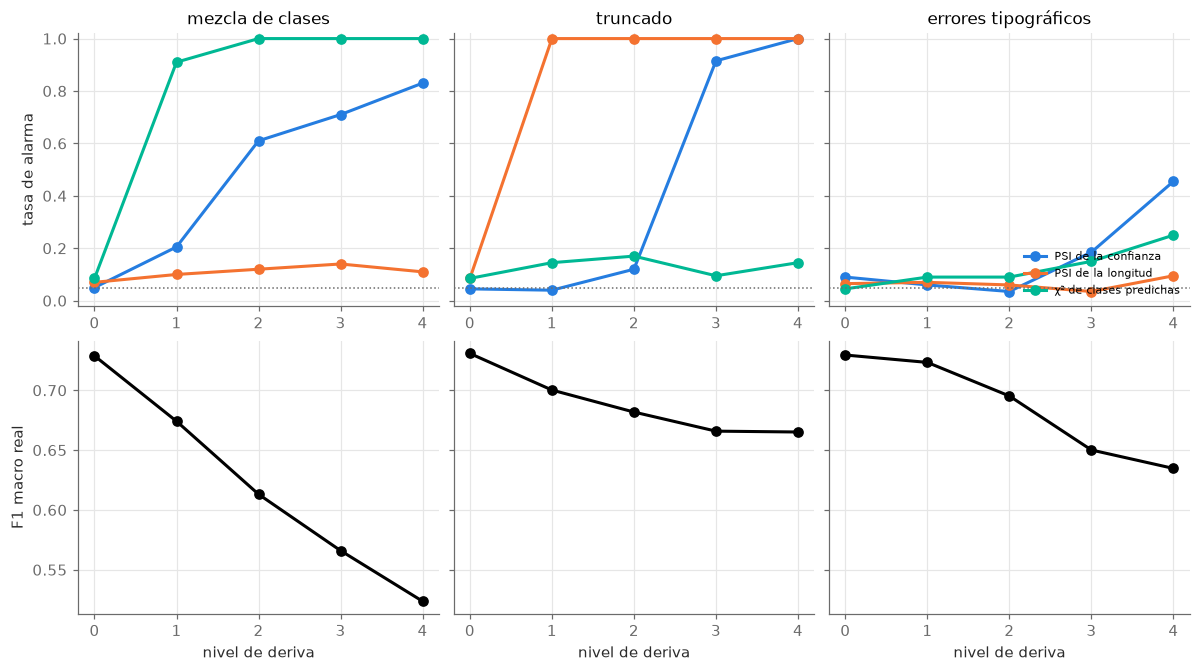

In [2]:
TD = need("mlops/drift/drift.pkl") if exists("mlops/drift/drift.pkl") else None
NAMES = {"psi_conf": "PSI de la confianza", "psi_len": "PSI de la longitud", "chi2_pred": "χ² de clases predichas", "mmd": "MMD (SVD-50)",
         "ks_conf": "KS de la confianza", "psi_mean": "PSI de la intensidad", "z_count": "z del n.º de instancias"}
SC = {"typos": "errores tipográficos", "truncado": "truncado", "prior": "mezcla de clases"}


def power_plot(P, dets, scen_col, scen_names, metric, metric_label):
    scs = list(dict.fromkeys(P[scen_col]))
    fig, axes = plt.subplots(2, len(scs), figsize=(3.6 * len(scs), 6), sharey="row")
    for j, sc in enumerate(scs):
        g = P[P[scen_col] == sc].sort_values("level")
        for k, d in enumerate(dets):
            axes[0, j].plot(g.level, g[f"alarm_{d}"], "o-", color=CAT[k], label=NAMES[d])
        axes[0, j].axhline(0.05, color=MUTED, ls=":", lw=1)
        axes[0, j].set(title=scen_names.get(sc, sc), ylim=(-0.02, 1.02))
        axes[1, j].plot(g.level, g[metric], "o-", color="black")
        axes[1, j].set(xlabel="nivel de deriva")
    axes[0, 0].set_ylabel("tasa de alarma"); axes[1, 0].set_ylabel(metric_label)
    axes[0, -1].legend(fontsize=7, loc="lower right")
    plt.show()


if TD is not None:
    tdets = [k for k, v in TD["thresholds"].items() if np.isfinite(v)]
    _off = [k for k in TD["thresholds"] if k not in tdets]
    md(f"Modelo monitoreado: {LBL_TXT.get(TD['served'], TD['served'])}. Umbrales (p95 sin deriva): "
       + ", ".join(f"{NAMES[k]} {TD['thresholds'][k]:.3g}" for k in tdets) + "."
       + (f" Sin calcular: {', '.join(NAMES[k] for k in _off)}. El MMD proyecta el TF-IDF del modelo servido con SVD-50; con "
          f"{LBL_TXT.get(TD['served'], TD['served'])} en producción no hay TF-IDF que proyectar, así que la deriva de covariables "
          "del texto queda cubierta solo por el PSI de la longitud. Un detector equivalente usaría los *embeddings* del propio "
          "modelo servido; no lo ejecutamos dentro del presupuesto." if _off else ""))
    power_plot(TD["power"], tdets, "scenario", SC, "f1", "F1 macro real")
else:
    md("El experimento de deriva de texto no terminó (`python scripts/mlops.py drift`).")

La fila superior es la potencia de cada detector (fracción de ventanas con alarma) y la inferior, la F1 macro real de esas ventanas, que en producción solo se conocería con etiquetas tardías. La línea punteada marca la tasa nominal de falsas alarmas.

Tasa empírica de falsas alarmas en el nivel 0 de cada escenario (ventanas sin deriva independientes de las que fijaron el umbral): PSI de la confianza 0.062, PSI de la longitud 0.073, χ² de clases predichas 0.072.

Con 600 ventanas sin deriva, el error estándar de una tasa de 0.05 es 0.009. PSI de la longitud y χ² de clases predichas superan la tasa nominal en más de dos errores estándar: el umbral es el percentil 95 de solo 200 ventanas, y el error de esa estimación se traslada a la tasa de falsas alarmas. Con más ventanas de referencia el umbral se estabiliza.

detector                    PSI de la confianza  PSI de la longitud  \
escenario            nivel                                            
errores tipográficos 1                    0.486               0.488   
                     2                    0.495               0.481   
                     3                    0.639               0.453   
                     4                    0.811               0.479   
mezcla de clases     1                    0.680               0.569   
                     2                    0.879               0.584   
                     3                    0.914               0.603   
                     4                    0.953               0.578   
truncado             1                    0.452               1.000   
                     2                    0.581               1.000   
                     3                    0.971               1.000   
                     4                    1.000               1.000   

detector                    χ² de clases predichas  
escenario            nivel                          
errores tipográficos 1                       0.524  
                     2                       0.537  
                     3                       0.606  
                     4                       0.704  
mezcla de clases     1                       0.981  
                     2                       1.000  
                     3                       1.000  
                     4                       1.000  
truncado             1                       0.603  
                     2                       0.620  
                     3                       0.568  
                     4                       0.628

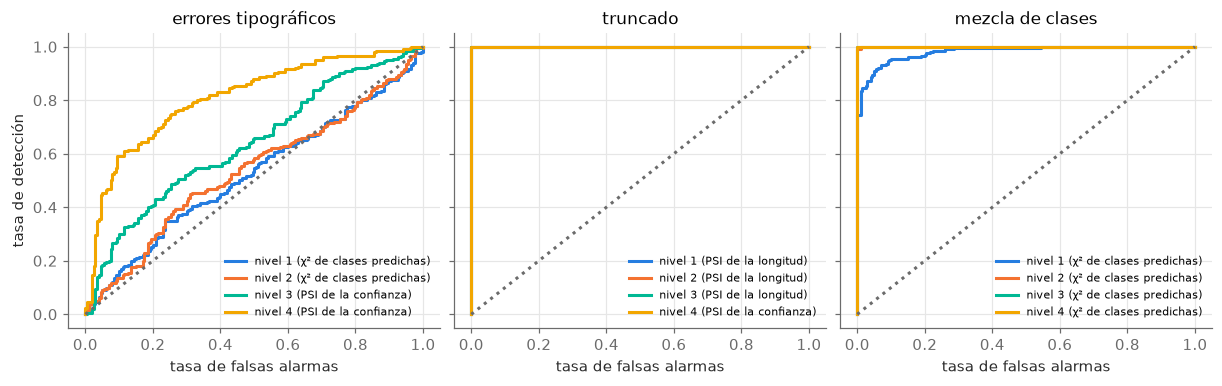

In [3]:
def roc_table(R, null, dets, scen_col):
    rows = []
    for (sc, lvl), g in R.groupby([scen_col, "level"]):
        if lvl == 0:
            continue
        for d in dets:
            y = np.r_[np.zeros(len(null)), np.ones(len(g))]
            rows.append(dict(escenario=sc, nivel=lvl, detector=NAMES[d], AUC=roc_auc_score(y, np.r_[null[d], g[d]])))
    return pd.DataFrame(rows).pivot_table(index=["escenario", "nivel"], columns="detector", values="AUC")


if TD is not None:
    R, null = TD["windows"], TD["null"]
    fa = R[R.level == 0][[f"alarm_{d}" for d in tdets]].mean()
    md("Tasa empírica de falsas alarmas en el nivel 0 de cada escenario (ventanas sin deriva independientes de las que fijaron el umbral): "
       + ", ".join(f"{NAMES[d]} {fa[f'alarm_{d}']:.3f}" for d in tdets) + ".")
    def _y(xs):
        return xs[0] if len(xs) == 1 else ", ".join(xs[:-1]) + " y " + xs[-1]

    _nfa = int((R.level == 0).sum())
    _ee = np.sqrt(0.05 * 0.95 / _nfa)
    _hi = [d for d in tdets if fa[f"alarm_{d}"] > 0.05 + 2 * _ee]
    md(f"Con {_nfa} ventanas sin deriva, el error estándar de una tasa de 0.05 es {_ee:.3f}. "
       + ("Todas las tasas quedan dentro de dos errores estándar de la nominal." if not _hi else
          f"{_y([NAMES[d] for d in _hi])} supera{'n' if len(_hi) > 1 else ''} la tasa nominal en más de dos errores estándar: el "
          f"umbral es el percentil 95 de solo {len(null)} ventanas, y el error de esa estimación se traslada a la tasa de falsas "
          "alarmas. Con más ventanas de referencia el umbral se estabiliza."))
    TAUC = roc_table(R.assign(scenario=R.scenario.map(SC)), null, tdets, "scenario")
    display(TAUC)
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
    for ax, sc in zip(axes, ["typos", "truncado", "prior"]):
        for k, lvl in enumerate(sorted(R[R.scenario == sc].level.unique())[1:]):
            g = R[(R.scenario == sc) & (R.level == lvl)]
            best = max(tdets, key=lambda d: roc_auc_score(np.r_[np.zeros(len(null)), np.ones(len(g))], np.r_[null[d], g[d]]))
            fpr, tpr, _ = roc_curve(np.r_[np.zeros(len(null)), np.ones(len(g))], np.r_[null[best], g[best]])
            ax.plot(fpr, tpr, color=CAT[k], label=f"nivel {lvl} ({NAMES[best]})")
        ax.plot([0, 1], [0, 1], ls=":", color=MUTED); ax.set(title=SC[sc], xlabel="tasa de falsas alarmas"); ax.legend(fontsize=7)
    axes[0].set_ylabel("tasa de detección")
    plt.show()

La tabla da el AUC de cada detector para separar ventanas con deriva de ventanas sin ella, por escenario y nivel; las curvas ROC muestran, para cada nivel, el mejor detector. Un AUC cercano a 0.5 significa que el detector no ve esa deriva.

In [4]:
if TD is not None:
    D = TD["delays"]
    D = D[D.detector.isin(tdets)]
    dl = D.assign(detectada=D.windows_to_detect.notna()).groupby(["scenario", "detector"]).agg(
        detectada=("detectada", "mean"), ventanas_mediana=("windows_to_detect", "median")).reset_index()
    dl["escenario"] = dl.scenario.map(SC); dl["detector"] = dl.detector.map(NAMES)
    display(dl.pivot_table(index="escenario", columns="detector", values="ventanas_mediana").rename_axis(None, axis=1))
    md("La tabla muestra la mediana del número de ventanas observadas hasta la primera alarma (1 = la primera ventana con deriva) en "
       f"una secuencia de 20 ventanas con deriva creciente (5 por nivel, niveles 1 a 4). Con ventanas de {TD['window']} documentos, "
       f"cada ventana equivale a {TD['window']} currículos recibidos.")
    P = TD["power"]
    drop = P.groupby("scenario").apply(lambda g: g.sort_values("level").f1.iloc[0] - g.sort_values("level").f1.iloc[-1], include_groups=False)
    md("Caída de F1 macro entre el nivel 0 y el nivel más severo: " + ", ".join(f"{SC[k]} {v:.3f}" for k, v in drop.items()) + ".")
    _amax = TAUC.groupby(level=0).max()
    _fa_mean = float(fa.mean())
    _bestd = dl.groupby("escenario").ventanas_mediana.min()
    _lines = []
    for sc_name, row in _amax.iterrows():
        seen = [d for d in row.index if row[d] >= 0.7]
        blind = [d for d in row.index if row[d] < 0.6]
        rr = dl[(dl.escenario == sc_name) & dl.detector.isin(seen)]
        best = rr.loc[rr.ventanas_mediana.idxmin()] if len(rr) else None
        _lines.append(f"- **{sc_name}**: "
                      + (f"lo detecta antes {best.detector} (mediana de {best.ventanas_mediana:.0f} {'ventana' if best.ventanas_mediana == 1 else 'ventanas'}, AUC máximo "
                         f"{row[best.detector]:.2f})" if best is not None else "ningún detector alcanza un AUC de 0.7")
                      + (f"; {_y(blind)} no ve{'n' if len(blind) > 1 else ''} esta deriva (AUC máximo < 0.6), así que sus "
                         "alarmas en este escenario son en su mayoría falsas alarmas" if blind else "") + ".")
    md("Resumen por escenario, con el AUC máximo entre niveles:\n\n" + "\n".join(_lines)
       + f"\n\nCon una tasa de falsas alarmas de {_fa_mean:.3f} por ventana, un detector ciego da su primera alarma, en promedio, "
       f"tras unas {1 / _fa_mean:.0f} ventanas; un retardo mediano de ese orden no indica detección. "
       f"La deriva que más tarda en verse es «{_bestd.idxmax()}»: el detector más rápido necesita una mediana de "
       f"{_bestd.max():.0f} ventanas.")

,PSI de la confianza,PSI de la longitud,χ² de clases predichas
escenario,,,
errores tipográficos,11.0,9.0,8.0
mezcla de clases,3.5,6.0,1.0
truncado,9.5,1.0,5.0


La tabla muestra la mediana del número de ventanas observadas hasta la primera alarma (1 = la primera ventana con deriva) en una secuencia de 20 ventanas con deriva creciente (5 por nivel, niveles 1 a 4). Con ventanas de 60 documentos, cada ventana equivale a 60 currículos recibidos.

Caída de F1 macro entre el nivel 0 y el nivel más severo: mezcla de clases 0.205, truncado 0.066, errores tipográficos 0.095.

Resumen por escenario, con el AUC máximo entre niveles:

- **errores tipográficos**: lo detecta antes χ² de clases predichas (mediana de 8 ventanas, AUC máximo 0.70); PSI de la longitud no ve esta deriva (AUC máximo < 0.6), así que sus alarmas en este escenario son en su mayoría falsas alarmas.
- **mezcla de clases**: lo detecta antes χ² de clases predichas (mediana de 1 ventana, AUC máximo 1.00).
- **truncado**: lo detecta antes PSI de la longitud (mediana de 1 ventana, AUC máximo 1.00).

Con una tasa de falsas alarmas de 0.069 por ventana, un detector ciego da su primera alarma, en promedio, tras unas 15 ventanas; un retardo mediano de ese orden no indica detección. La deriva que más tarda en verse es «errores tipográficos»: el detector más rápido necesita una mediana de 8 ventanas.

## Imágenes

Escenarios sobre ventanas de 10 imágenes de test, 200 repeticiones por nivel, con el modelo de segmentación servido (ONNX en CPU): desenfoque, ruido gaussiano y gradiente de iluminación con cuatro niveles de severidad crecientes, y un cambio de la mezcla de tipos celulares (ventanas con el 25 al 100 % de astrocitos). Las señales son las que la API registra sin etiquetas: intensidad media y DE, fracción de primer plano, número de instancias y confianza media del primer plano.

Modelo monitoreado: U-Net++. Umbrales (p95 sin deriva): KS de la confianza 0.417, PSI de la intensidad 6.28, MMD (señales de imagen estandarizadas) 0.0542, z del n.º de instancias 1.98.

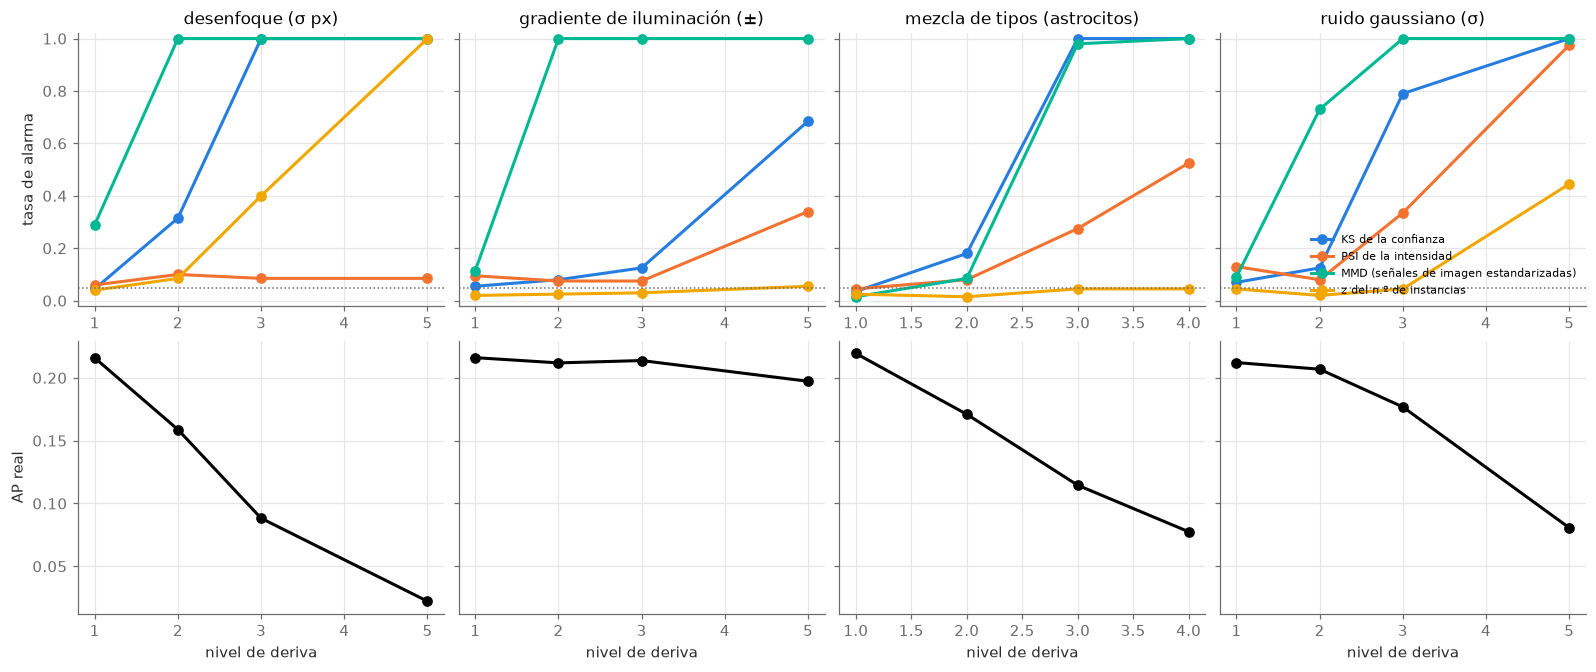

detector                            KS de la confianza  \
escenario                    nivel                       
desenfoque (σ px)            1                   0.462   
                             2                   0.772   
                             3                   1.000   
                             5                   1.000   
gradiente de iluminación (±) 1                   0.513   
                             2                   0.509   
                             3                   0.584   
                             5                   0.954   
mezcla de tipos (astrocitos) 1                   0.435   
                             2                   0.754   
                             3                   0.994   
                             4                   1.000   
ruido gaussiano (σ)          1                   0.533   
                             2                   0.583   
                             3                   0.954   
                             5                   1.000   

detector                            MMD (señales de imagen estandarizadas)  \
escenario                    nivel                                           
desenfoque (σ px)            1                                       0.852   
                             2                                       1.000   
                             3                                       1.000   
                             5                                       1.000   
gradiente de iluminación (±) 1                                       0.668   
                             2                                       1.000   
                             3                                       1.000   
                             5                                       1.000   
mezcla de tipos (astrocitos) 1                                       0.415   
                             2                                       0.701   
                             3                                       0.988   
                             4                                       1.000   
ruido gaussiano (σ)          1                                       0.585   
                             2                                       0.958   
                             3                                       1.000   
                             5                                       1.000   

detector                            PSI de la intensidad  \
escenario                    nivel                         
desenfoque (σ px)            1                     0.478   
                             2                     0.535   
                             3                     0.507   
                             5                     0.507   
gradiente de iluminación (±) 1                     0.509   
                             2                     0.504   
                             3                     0.465   
                             5                     0.759   
mezcla de tipos (astrocitos) 1                     0.444   
                             2                     0.501   
                             3                     0.691   
                             4                     0.852   
ruido gaussiano (σ)          1                     0.576   
                             2                     0.529   
                             3                     0.785   
                             5                     0.994   

detector                            z del n.º de instancias  
escenario                    nivel                           
desenfoque (σ px)            1                        0.493  
                             2                        0.552  
                             3                        0.885  
                             5                        1.000  
gradiente de iluminación (±) 1                        0.517  
                             2     

AP medio de ventanas sin deriva: 0.211. AP en el nivel más severo: desenfoque (σ px) 0.022, gradiente de iluminación (±) 0.197, mezcla de tipos (astrocitos) 0.078, ruido gaussiano (σ) 0.081.

Comparación de detectores por escenario. En los niveles severos casi todos llegan a AUC 1, así que los comparamos en el nivel más leve:

- **desenfoque (σ px)**: en el nivel más leve detecta mejor MMD (señales de imagen estandarizadas) (AUC 0.85); PSI de la intensidad no la ve en ningún nivel (AUC < 0.6).
- **gradiente de iluminación (±)**: en el nivel más leve detecta mejor MMD (señales de imagen estandarizadas) (AUC 0.67); z del n.º de instancias no la ve en ningún nivel (AUC < 0.6). El AP cae solo 0.014 en el nivel más severo: es una deriva visible para el monitoreo que apenas daña al modelo, y una alarma sobre ella debe confirmarse con la métrica real antes de reentrenar.
- **mezcla de tipos (astrocitos)**: en el nivel más leve ningún detector la ve (AUC máximo 0.49); en el nivel más severo, KS de la confianza llega a 1.00.
- **ruido gaussiano (σ)**: en el nivel más leve ningún detector la ve (AUC máximo 0.58); en el nivel más severo, KS de la confianza llega a 1.00.

In [5]:
ID = need("mlops/drift_image/drift_image.pkl") if exists("mlops/drift_image/drift_image.pkl") else None
if ID is not None:
    NAMES = {**NAMES, "mmd": "MMD (señales de imagen estandarizadas)"}
    idets = list(ID["thresholds"])
    md(f"Modelo monitoreado: {LBL_SEG.get(ID['served'], ID['served'])}. Umbrales (p95 sin deriva): " + ", ".join(f"{NAMES[k]} {v:.3g}" for k, v in ID["thresholds"].items()) + ".")
    Pw = ID["power"][ID["power"].scenario != "ninguna"]
    power_plot(Pw, idets, "scenario", {}, "ap", "AP real")
    Ri = ID["windows"]; nulli = Ri[Ri.scenario == "ninguna"]
    TAUCi = roc_table(Ri[Ri.scenario != "ninguna"], nulli, idets, "scenario")
    display(TAUCi)
    base = nulli.ap.mean()
    worst = Pw.loc[Pw.groupby("scenario")["level"].idxmax()]
    md(f"AP medio de ventanas sin deriva: {base:.3f}. AP en el nivel más severo: "
       + ", ".join(f"{s} {a:.3f}" for s, a in zip(worst.scenario, worst.ap)) + ".")
    _lv1 = TAUCi.groupby(level=0).head(1).droplevel(1)          # nivel más leve de cada escenario
    _am = TAUCi.groupby(level=0).max()
    _apw = dict(zip(worst.scenario, worst.ap))
    _li = []
    for sc_name, row in _lv1.iterrows():
        best_d = row.idxmax(); blind = [d for d in _am.columns if _am.loc[sc_name, d] < 0.6]
        drop_ = base - _apw.get(sc_name, np.nan)
        _li.append(f"- **{sc_name}**: "
                   + (f"en el nivel más leve detecta mejor {best_d} (AUC {row[best_d]:.2f})" if row[best_d] >= 0.6 else
                      f"en el nivel más leve ningún detector la ve (AUC máximo {row[best_d]:.2f}); en el nivel más severo, "
                      f"{_am.loc[sc_name].idxmax()} llega a {_am.loc[sc_name].max():.2f}")
                   + (f"; {_y(blind)} no la ve{'n' if len(blind) > 1 else ''} en ningún nivel (AUC < 0.6)" if blind else "")
                   + (f". El AP cae solo {drop_:.3f} en el nivel más severo: es una deriva visible para el monitoreo que apenas daña "
                      "al modelo, y una alarma sobre ella debe confirmarse con la métrica real antes de reentrenar" if drop_ < 0.03 else "")
                   + ".")
    md("Comparación de detectores por escenario. En los niveles severos casi todos llegan a AUC 1, así que los comparamos en el "
       "nivel más leve:\n\n" + "\n".join(_li))
else:
    md("El experimento de deriva de imágenes no terminó (`python scripts/mlops.py drift-image`).")

El cambio de mezcla de tipos celulares es una deriva de covariables sin daño de la imagen: cada imagen sigue siendo de la distribución de entrenamiento, pero la proporción cambia. Lo incluimos porque un laboratorio que empieza a cultivar otra línea celular produce exactamente esa deriva, y la métrica de la ventana cambia porque el AP difiere entre tipos (capítulo {doc}`13_seg_resultados`).

## Política de alerta y reentrenamiento

**Costos.** Una falsa alarma cuesta una revisión manual de la ventana (del orden de una hora de una persona). Una deriva no detectada cuesta las decisiones tomadas con un modelo degradado hasta la siguiente revisión programada: currículos mal clasificados que no llegan a la persona correcta, o conteos celulares sesgados en un experimento. En los dos dominios el segundo costo es mayor, así que preferimos un umbral sensible y una confirmación antes de actuar.

**Regla propuesta.**

1. *Alarma*: un detector supera su umbral (p95 sin deriva) en **dos ventanas consecutivas**. Con independencia entre ventanas, una tasa de falsas alarmas *p* por ventana baja a *p*² por par de ventanas (del 5 % al 0.25 % con la tasa nominal).
2. *Diagnóstico*: se etiqueta a mano una muestra de la ventana (30 currículos o 5 imágenes) y se mide la métrica real. Si la caída supera δ (0.02 de F1 macro o de AP), se confirma la deriva de concepto.
3. *Reentrenamiento*: con la deriva confirmada, se reentrena con los datos nuevos etiquetados y se vuelve a ejecutar la evaluación completa (`make eval analysis`).
4. *Despliegue del modelo nuevo*:
   - **Sombra**: el modelo nuevo recibe copia del tráfico durante una semana sin responder; comparamos predicciones y señales de deriva con el modelo en producción.
   - **Canario**: el 10 % de las peticiones va al modelo nuevo; si su conjunto dorado, su latencia p95 y su tasa de errores se mantienen, pasa al 100 %.
   - ***Rollback***: si cualquier señal empeora, `python scripts/track_mlflow.py rollback <tipo>` devuelve el alias `production` a la versión anterior y se vuelve a desplegar la carpeta registrada de esa versión.

Con la regla de dos ventanas, el retardo de detección aumenta en una ventana respecto de los valores de la tabla de retardos.